# Dataset visualisation and  cleaning

<div class="alert alert-block alert-success">
<b> Data cleaning </b> can be a tedious task. 
According to IBM Data Analytics you can expect to spend up to 80% of your time cleaning data. ok.
</div>

## Dataset description and visualisation

<div class="alert alert-block alert-success">
Data visualization is an essential aspect of data analysis that focuses on visually representing data. It provides a visual summary that aids in
processing and understanding information through images, maps, and graphs, simplifying observation, analysis, and comprehension. This is
particularly beneficial for large datasets, where manual processing can be tedious. Moreover, it helps highlight trends, patterns, and outliers.
Python offers a variety of libraries for data visualization, including Plotly, Matplotlib, and Seaborn.
</div>

<div class="alert alert-block alert-warning">Hepatitis is an inflammation of the liver. Most hepatitis patients are often asymptomatic. The Hepatitis dataset contains records of hepatitis cases in individuals and predicts patient survivability. For more details on this dataset, visit: https://archive.ics.
uci.edu/dataset/46/hepatitis <div>

<div class="alert alert-block alert-danger">
    
1. Import the Hepatitis dataset 
2. Print the first 10 samples
3. Print 3 random samples
4. Print the last 5 samples
5. Display the following information about the dataset: columns, number of missing values in each column, and the type of features, all in one instruction.
5. Display only the columns and their types (whether they are numerical or categorical).
6. Display the number of samples and features.
7. Display statistics for all numerical features: count, mean, standard deviation, quantiles, minimum, and maximum values.
8. Verify if the dataset is balanced using a count and a plot.
9. Using the pandas library, perform a line plot, histogram, and box plot for continuous values only. In the line plot, why is the line graph of the
feature ”protime” not continuous?
<\div>

<b>A standard deviation (or σ) </b> is a measure of how dispersed the data is in relation to the mean.

<b> The median </b> is the middle value in a list ordered from smallest to largest.

<b> 25%, 50%, and 75% </b> present the Q1, Median, and Q3 values. 
![title](fig1.png)

## Dataset cleaning

<div class="alert alert-block alert-success">
Data cleaning is a crucial step in the machine learning process for optimal algorithm performance. It involves identifying and correcting issues such as missing values, duplicates, and irrelevant data to ensure accurate, consistent, high-quality, and error-free datasets. Common techniques used in data cleaning include handling missing values, removing duplicates, data type conversion, and outlier detection.
</div>

### Missing values

<div class="alert alert-block alert-success">
Handling missing data is a critical aspect of data preprocessing in machine learning. Effective strategies include imputing missing values
using statistical methods, removing records with missing values, or employing advanced imputation techniques. Each approach has its advantages and limitations, and choosing the right method is essential
for preventing biases and maintaining the integrity of analyses.
</div>

<div class="alert alert-block alert-danger"> 
    
1. Why is data missing? 
2. Print all samples that contain missing values.
3. Print features that contain missing values.
5. Print samples with features that contain missing values.
6. Identify the number of missing values in each feature.
7. Create a new dataframe from the first one and drop samples containing
missing values.
8. Create a new dataframe from the first one and delete columns contain-
ing missing values. Is deleting missing values a solution?
9. Replace missing values using the mean (for continuous values) or mode
(for categorical values) and print the number of missing values after
imputation.
<div/>

### Outliers

<div class="alert alert-block alert-success">
Outliers are data points that significantly deviate from the norm and can arise from various causes, including errors, anomalies, or data variability. Their presence can negatively impact the performance of machine learning models, making it essential to manage outliers for obtaining accurate results. To address outliers, it is important to identify and manage them effectively by either deciding whether to remove them or transforming them to minimize their impact on analysis.
<div/>

<div class="alert alert-block alert-danger">

1. Find  outliers in the data using box plots.
2. Compute the Interquartile Range (IQR), upper and lower bounds for
both the alkaline phosphate and bilirubin features, and detect outliers.
3. Handle outliers using an automatic method (not mean or median).
<div/>

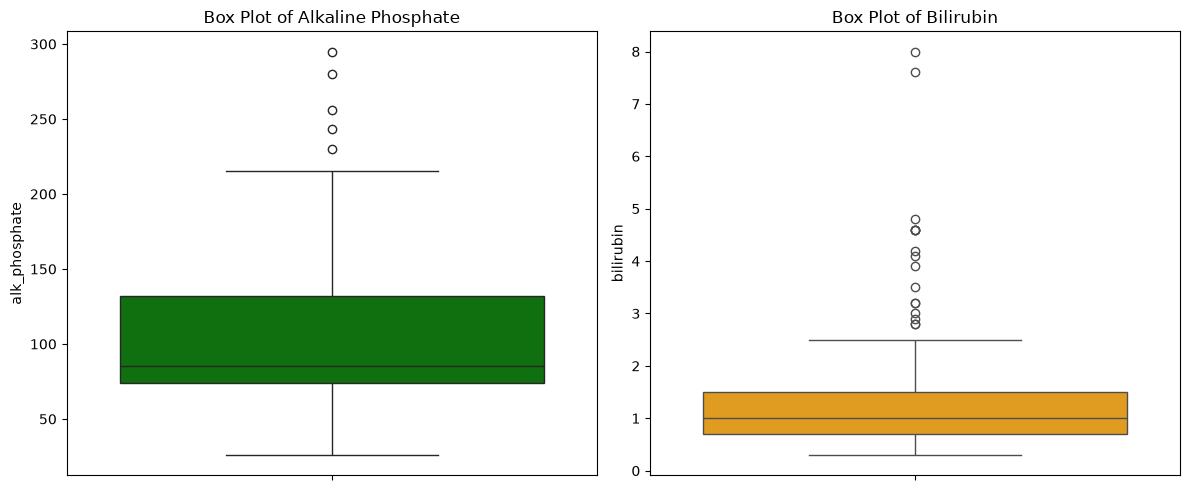

=== Feature: alk_phosphate ===
Q1: 74.25, Q3: 132.25, IQR: 58.00
Lower Bound: -12.75, Upper Bound: 219.25
Number of Outliers: 5
Outlier Values: [280.0, 230.0, 256.0, 243.0, 295.0]

=== Feature: bilirubin ===
Q1: 0.70, Q3: 1.50, IQR: 0.80
Lower Bound: -0.50, Upper Bound: 2.70
Number of Outliers: 17
Outlier Values: [4.6, 3.5, 4.1, 2.8, 4.6, 3.0, 4.8, 4.6, 3.2, 3.2, 2.9, 2.8, 4.6, 8.0, 3.9, 4.2, 7.6]

Outliers capped successfully!


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv('hepatitis.csv')

target_features = ['alk_phosphate', 'bilirubin']

# --- 1. Plot Box Plots for alk_phosphate and bilirubin only ---
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Plot Alkaline Phosphate
sns.boxplot(y=df['alk_phosphate'], ax=axes[0], color='green')
axes[0].set_title('Box Plot of Alkaline Phosphate')
axes[0].set_ylabel('alk_phosphate')

# Plot Bilirubin
sns.boxplot(y=df['bilirubin'], ax=axes[1], color='oraange')
axes[1].set_title('Box Plot of Bilirubin')
axes[1].set_ylabel('bilirubin')

plt.tight_layout()
plt.show()

# --- 2. Compute IQR, Upper and Lower Bounds, and Detect Outliers ---
for col in target_features:
    series = df[col].dropna()
    
    Q1 = series.quantile(0.25)
    Q3 = series.quantile(0.75)
    IQR = Q3 - Q1
    
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    outliers = series[(series < lower_bound) | (series > upper_bound)]
    
    print(f"=== Feature: {col} ===")
    print(f"Q1: {Q1:.2f}, Q3: {Q3:.2f}, IQR: {IQR:.2f}")
    print(f"Lower Bound: {lower_bound:.2f}, Upper Bound: {upper_bound:.2f}")
    print(f"Number of Outliers: {len(outliers)}")
    print(f"Outlier Values: {outliers.tolist()}\n")

# --- 3. Handle Outliers using Automatic Capping (Winsorization) ---
df_capped = df.copy()

for col in target_features:
    Q1 = df_capped[col].quantile(0.25)
    Q3 = df_capped[col].quantile(0.75)
    IQR = Q3 - Q1
    
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    # Clip extreme values outside the bounds
    df_capped[col] = df_capped[col].clip(lower=lower_bound, upper=upper_bound)

print("Outliers capped successfully!")

## Study of correlation and feature selection

<div class="alert alert-block alert-success">
Feature selection is a crucial process in machine learning that involves
automatically identifying the most relevant features in a dataset that
contribute to the decision-making process. Including irrelevant and
highly correlated features can lead to decreased accuracy. This process
also helps to manage high-dimensional data by reducing overfitting,
enhancing model accuracy, and decreasing training time.
<div/>

<div class="alert alert-block alert-danger"> 

1. Drop the feature ”Sex”.
2. Plot the Pearson correlation heatmap to observe the correlation of in-
dependent variables with the output variable.
3. Only select features that have an absolute correlation above 0.5 with
the output variable.
4. Drop the features that are highly correlated with malaise.
5. Should features be correlated?
<div/>

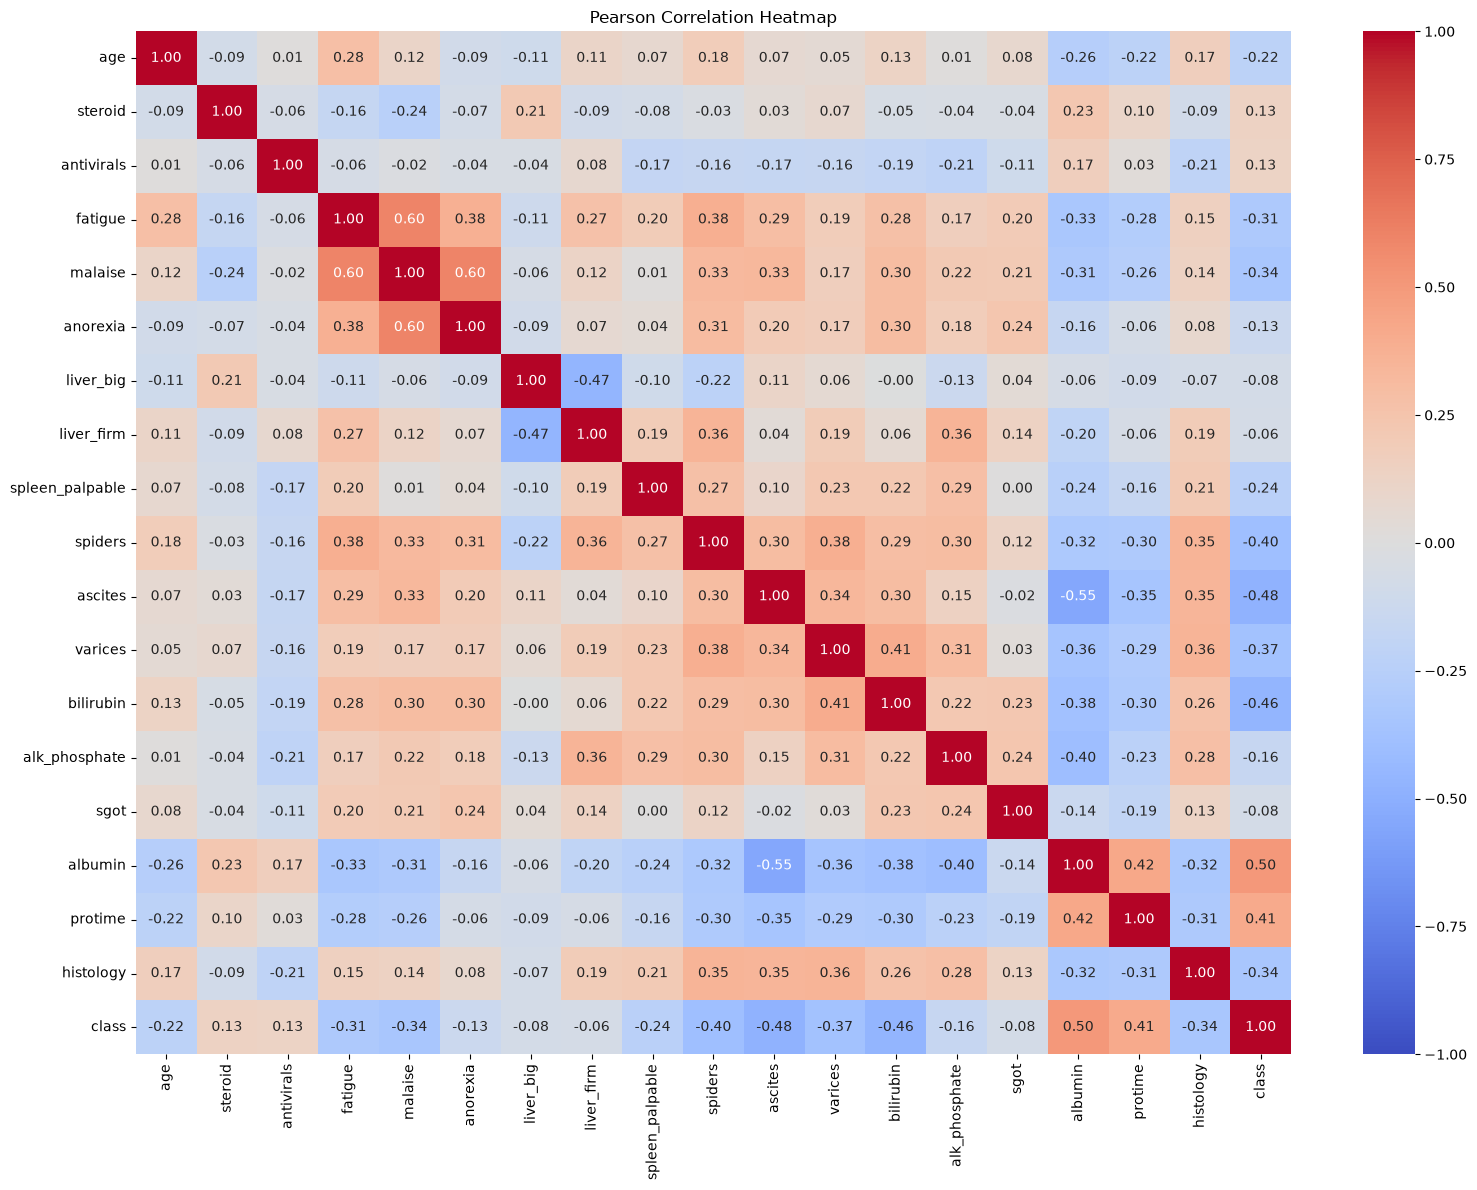

Correlation with class (sorted):
albumin            0.503272
ascites            0.477882
bilirubin          0.463752
protime            0.409160
spiders            0.398308
varices            0.368846
malaise            0.337859
histology          0.337856
fatigue            0.309269
spleen_palpable    0.238734
age                0.219647
alk_phosphate      0.161204
steroid            0.134700
anorexia           0.132172
antivirals         0.130196
sgot               0.077678
liver_big          0.077630
liver_firm         0.063155
Name: class, dtype: float64 

Selected features (|r| > 0.5): ['albumin'] 

Features highly correlated with malaise (|r| > 0.7): []
Dropped from selected set: []

Final columns: ['albumin', 'class']


In [3]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Load the dataset
df = pd.read_csv('hepatitis.csv')

# 1. Drop the feature "sex"
df = df.drop(columns=['sex'], errors='ignore')

# Preprocessing: convert to numeric, keeping missing values as NaN (not -1)
df['class'] = df['class'].map({'live': 1, 'die': 0})
bool_map = {True: 1.0, False: 0.0, 'True': 1.0, 'False': 0.0}
for col in df.columns:
    if df[col].dtype == 'object' or df[col].dtype == 'bool':
        df[col] = df[col].map(bool_map).astype(float)

# 2. Pearson correlation heatmap
corr_matrix = df.corr(method='pearson')
plt.figure(figsize=(16, 12))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1)
plt.title("Pearson Correlation Heatmap")
plt.tight_layout()
plt.show()

# 3. Keep only features with |r| > 0.5 with the output variable
target_corr = corr_matrix['class'].abs().drop('class')
print("Correlation with class (sorted):")
print(target_corr.sort_values(ascending=False), "\n")

selected = target_corr[target_corr > 0.5].index.tolist()
print("Selected features (|r| > 0.5):", selected, "\n")
df_selected = df[selected + ['class']]

# 4. Drop selected features highly correlated with malaise
threshold = 0.7  # state this choice in your report
malaise_corr = corr_matrix['malaise'].abs().drop('malaise')
to_drop = [c for c in malaise_corr[malaise_corr > threshold].index
           if c in df_selected.columns]
print(f"Features highly correlated with malaise (|r| > {threshold}):",
      malaise_corr[malaise_corr > threshold].index.tolist())
print("Dropped from selected set:", to_drop)

df_final = df_selected.drop(columns=to_drop)
print("\nFinal columns:", df_final.columns.tolist())

# 5. Should features be correlated?
# - Feature vs target: yes. Strong correlation means predictive information.
# - Feature vs feature: no. Redundant features cause multicollinearity,
#   unstable coefficients, and extra dimensionality without added information.

## Data splitting

<div class="alert alert-block alert-success">
Data splitting is the process of dividing a dataset into two or more subsets, typically comprising a training set and a testing set. This ensures that models are trained on one subset of the data (training set) while being evaluated on another (test set), which helps effectively assess their performance and improve generalization. In Python, the scikit-learn library is a popular choice for implementing data splitting, offering various functions and classes to facilitate this essential process.
<div/>

<div class="alert alert-block alert-danger">

1. Split the data into training and test sets using the hold-out and stratified hold-out strategies.
2. Display the number of samples in each class for both strategies in the training and test sets.
<div/>

In [2]:
import pandas as pd
from sklearn.model_selection import train_test_split

# 1. Load the dataset
df = pd.read_csv('hepatitis.csv')

# Separate features (X) and target (y)
X = df.drop(columns=['class'])
y = df['class']

# --- Standard Hold-Out Strategy ---
X_train_ho, X_test_ho, y_train_ho, y_test_ho = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# --- Stratified Hold-Out Strategy ---
X_train_strat, X_test_strat, y_train_strat, y_test_strat = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 2. Display sample counts in each class for both strategies
print("==========================================")
print("1. STANDARD HOLD-OUT SPLIT (Random)")
print("==========================================")
print("Training Set Class Counts:")
print(y_train_ho.value_counts())
print("\nTest Set Class Counts:")
print(y_test_ho.value_counts())

print("\n==========================================")
print("2. STRATIFIED HOLD-OUT SPLIT")
print("==========================================")
print("Training Set Class Counts:")
print(y_train_strat.value_counts())
print("\nTest Set Class Counts:")
print(y_test_strat.value_counts())

1. STANDARD HOLD-OUT SPLIT (Random)
Training Set Class Counts:
class
live    99
die     25
Name: count, dtype: int64

Test Set Class Counts:
class
live    24
die      7
Name: count, dtype: int64

2. STRATIFIED HOLD-OUT SPLIT
Training Set Class Counts:
class
live    98
die     26
Name: count, dtype: int64

Test Set Class Counts:
class
live    25
die      6
Name: count, dtype: int64
